
# STRATUM — Process Sensor and Correlation Analysis

### Objective

Explore the Advanced Process Control (APC) sensor variables
recorded during semiconductor AlCu Physical Vapor Deposition.

Investigate their completeness, distributions, variability,
correlations, and potential usefulness for virtual metrology.

### Research Questions

1. Which manufacturing process variables are available?
2. Which sensors have substantial missing data?
3. How do important process variables behave?
4. Which APC variables correlate with film thickness?
5. Which APC variables correlate with sheet resistance?
6. Which sensors are strongly correlated with each other?
7. Does sensor missingness vary across equipment?

### Methodological Notes

- The original dataset remains unchanged.
- Post-process metrology measurements are excluded from APC inputs.
- This is exploratory analysis, not final ML feature selection.
- Final feature selection and preprocessing must use training data only.
- Correlation does not establish causation.

In [2]:
# Import libraries and load data

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

filename = "apc_spc_AlCu_inputs_outputs.csv"

current_dir = Path.cwd()

csv_path = current_dir / "data" / "raw" / filename

if not csv_path.exists():
    csv_path = current_dir.parent / "data" / "raw" / filename

if not csv_path.exists():
    raise FileNotFoundError(
        f"Dataset not found. Current directory: {current_dir}"
    )

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False
)

print("STRATUM - Process Sensor Analysis")
print("Dataset shape:", df.shape)
print("Dataset loaded successfully!")

STRATUM - Process Sensor Analysis
Dataset shape: (5208, 178)
Dataset loaded successfully!


## 1. APC Sensor Identification

Separate process-input variables from wafer metadata, metrology measurements, and quality indicators.

Only suitable process-time APC variables will be considered as inputs for virtual metrology models.

In [3]:
#  Identify APC sensor columns

metadata_cols = [
    "bat_id", "wafer_id", "lot",
    "equipment", "machine",
    "batchstart", "batchend", "slot",
    "runstart", "runend"
]

thickness_cols = [
    f"RAW_VALUE_t_{i}" for i in range(1, 18)
]

resistance_cols = [
    f"RAW_VALUE_r_{i}" for i in range(1, 18)
]

resistivity_cols = [
    f"RAW_VALUE_{i}" for i in range(1, 18)
]

average_cols = [
    "mean_thickness", "mean_resistance"
]

quality_cols = [
    "stable_state",
    "quality_thickness",
    "quality_resistance",
    "quality_resistivity",
    "quality_overall"
]

excluded_cols = set(
    metadata_cols
    + thickness_cols
    + resistance_cols
    + resistivity_cols
    + average_cols
    + quality_cols
)

apc_cols = [
    col for col in df.columns
    if col not in excluded_cols
]

print("Total columns:", len(df.columns))
print("APC process variables:", len(apc_cols))
print("Excluded non-APC columns:", len(excluded_cols))

assert len(apc_cols) == 110
assert all(
    pd.api.types.is_numeric_dtype(df[col])
    for col in apc_cols
)

print("\nFirst 20 APC variables:")

for col in apc_cols[:20]:
    print(col)


Total columns: 178
APC process variables: 110
Excluded non-APC columns: 68

First 20 APC variables:
AMPS_TARGET_20_90_DELTA_DEP1
AMPS_TARGET_20_90_DEP1_M
AMPS_TARGET_20_90_DEP1_SPS
AMPS_TARGET_20_90_DEP1_SPS_M
AMPS_TARGET_20_90_DEP1_SPS_X
AMPS_TARGET_20_90_DEP1_X
AMPS_TARGET_20_95_DELTA_DEP1
AMPS_TARGET_20_95_DEP1_M
AMPS_TARGET_20_95_DEP1_SPS
AMPS_TARGET_20_95_DEP1_SPS_M
AMPS_TARGET_20_95_DEP1_SPS_X
AMPS_TARGET_20_95_DEP1_X
AMPS_TARGET_DEP1_A
AMPS_TARGET_DEP1_A_MR
AMPS_TARGET_DEP1_S
AMPS_TARGET_RECIPE_A
AMPS_TARGET_RUN_A
AMPS_TARGET_RUN_S
AMPS_TARGET_SPS_DEP1_A
AMPS_TARGET_SPS_DEP1_S


## 2. Manufacturing Sensor Categories

Group APC sensor variables by their descriptive names to understand the types of semiconductor process parameters available for analysis.

Categories are based on naming conventions and are not independently verified physical classifications.

,Sensor Count
Category,
Electrical Current,20
Other Process Variables,18
Pressure,13
Component Lifetime,11
Temperature,11
Process Timing,11
Power,9
Voltage,9
Gas,4


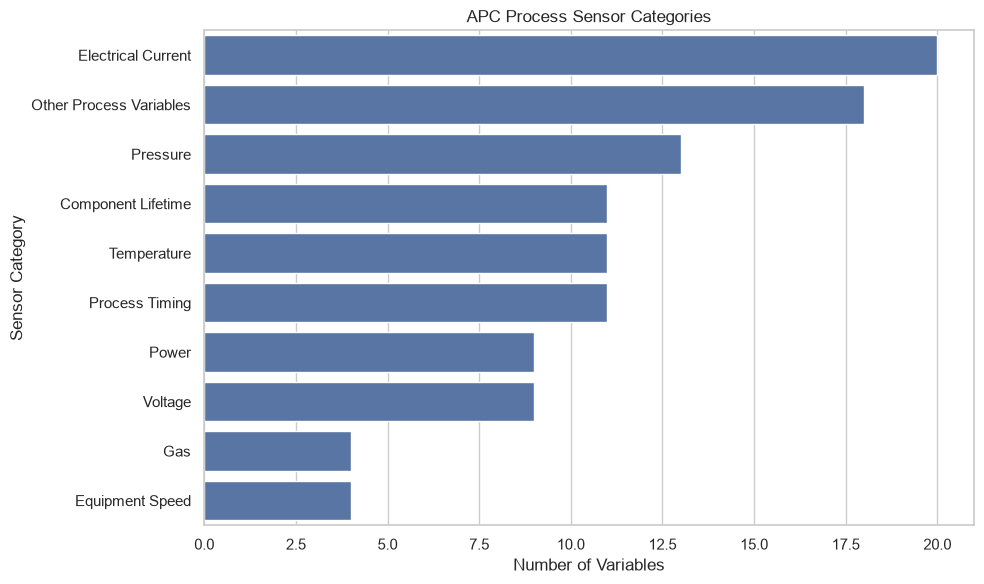

In [4]:
# Categorise APC sensors

def classify_sensor(name):
    name = name.upper()

    if name.startswith("AMPS_"):
        return "Electrical Current"
    elif name.startswith("VOLTS_"):
        return "Voltage"
    elif name.startswith("POWER_"):
        return "Power"
    elif name.startswith("PRESS_"):
        return "Pressure"
    elif name.startswith("TEMP_"):
        return "Temperature"
    elif name.startswith("GAS"):
        return "Gas"
    elif name.startswith("SPEED_"):
        return "Equipment Speed"
    elif name.startswith("T_"):
        return "Process Timing"
    elif name.startswith("LIFE_"):
        return "Component Lifetime"
    else:
        return "Other Process Variables"

sensor_categories = pd.DataFrame({
    "Sensor": apc_cols,
    "Category": [
        classify_sensor(col) for col in apc_cols
    ]
})

category_counts = (
    sensor_categories["Category"]
    .value_counts()
)

display(category_counts.to_frame("Sensor Count"))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("APC Process Sensor Categories")
plt.xlabel("Number of Variables")
plt.ylabel("Sensor Category")

plt.tight_layout()
plt.show()

## 3. APC Sensor Missingness

Identify process sensors with the highest percentage of missing observations.

Investigate missingness before determining whether features should be imputed, removed, or treated differently across equipment.

APC sensors: 110
APC sensors with missing values: 47
APC sensors above 50% missing: 11


,Missing %
WAFERCOUNT_RECIPE_MR,68.57
VOLTS_TARGET_DEP1_G,67.86
GAS2_DEP1_S,64.94
WAFERCOUNT_MR,61.54
LIFE_TARGET_RUN_I,61.12
T_RUN_ENG,54.47
PRESS_TRANSFER_RUN_X,54.19
PRESS_CHAMBER_DEP1_R,54.19
PRESS_IONGAUGE_BP_I_ENG,52.40
PRESS_IONGAUGE_BP_I_ENG1,50.56


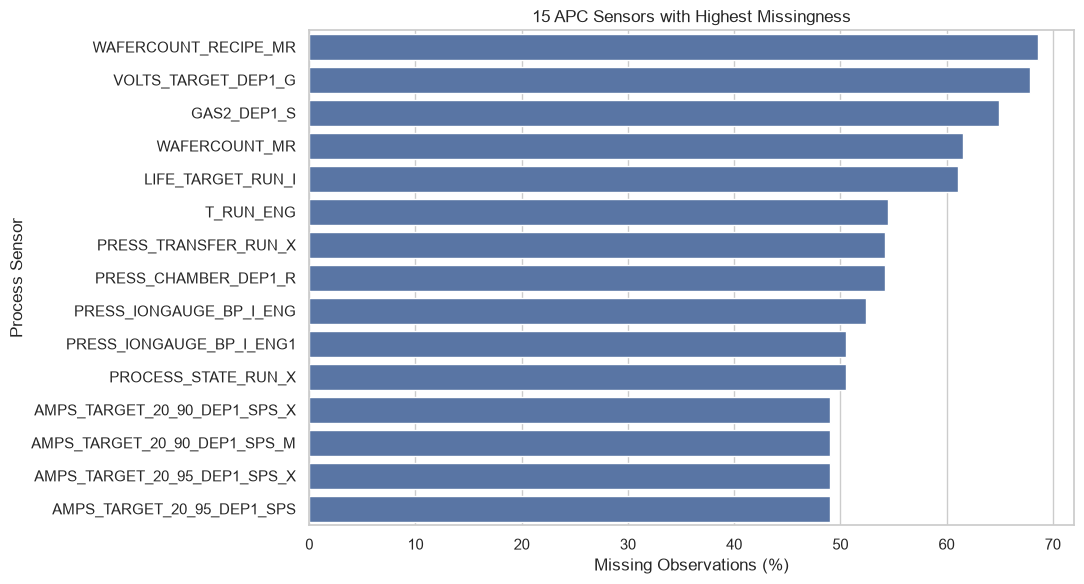

In [5]:
#  APC missingness

apc_missing = (
    df[apc_cols].isna().mean() * 100
).sort_values(ascending=False)

missing_sensor_count = int(
    (apc_missing > 0).sum()
)

print("APC sensors:", len(apc_cols))
print("APC sensors with missing values:",
      missing_sensor_count)

print("APC sensors above 50% missing:",
      int((apc_missing > 50).sum()))

display(
    apc_missing.head(15)
    .round(2)
    .to_frame("Missing %")
)

top_missing = apc_missing.head(15)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_missing.values,
    y=top_missing.index
)

plt.title("15 APC Sensors with Highest Missingness")
plt.xlabel("Missing Observations (%)")
plt.ylabel("Process Sensor")

plt.tight_layout()
plt.show()


## 4. Process Sensor Distributions

Visualise representative numeric process variables from electrical, pressure, temperature, gas, and process timing categories.

Investigate variability, unusual values, and possible differences in equipment operating conditions.

In [6]:
# Select representative sensors

preferred_categories = [
    "Power",
    "Pressure",
    "Temperature",
    "Gas",
    "Process Timing",
    "Electrical Current"
]

selected_sensors = []

for category in preferred_categories:

    candidates = sensor_categories.loc[
        sensor_categories["Category"] == category,
        "Sensor"
    ].tolist()

    # Prefer better-populated sensors
    candidates = sorted(
        candidates,
        key=lambda col: df[col].isna().mean()
    )

    # Exclude constant sensors
    candidates = [
        col for col in candidates
        if df[col].nunique(dropna=True) > 1
    ]

    if candidates:
        selected_sensors.append(candidates[0])

print("Selected representative sensors:")

for sensor in selected_sensors:
    print(
        sensor,
        "| Missing:",
        f"{df[sensor].isna().mean() * 100:.2f}%"
    )


Selected representative sensors:
POWER_SPS_DELTA_DEP1_A | Missing: 0.00%
PRESS_CHAMBER_DEP1_A | Missing: 0.00%
TEMP_CRYOFIRSTSTAGE_RUN_X | Missing: 0.00%
GAS1_DEP1_A | Missing: 0.00%
T_DEP1_PROCESS | Missing: 0.00%
AMPS_TARGET_20_90_DELTA_DEP1 | Missing: 0.00%


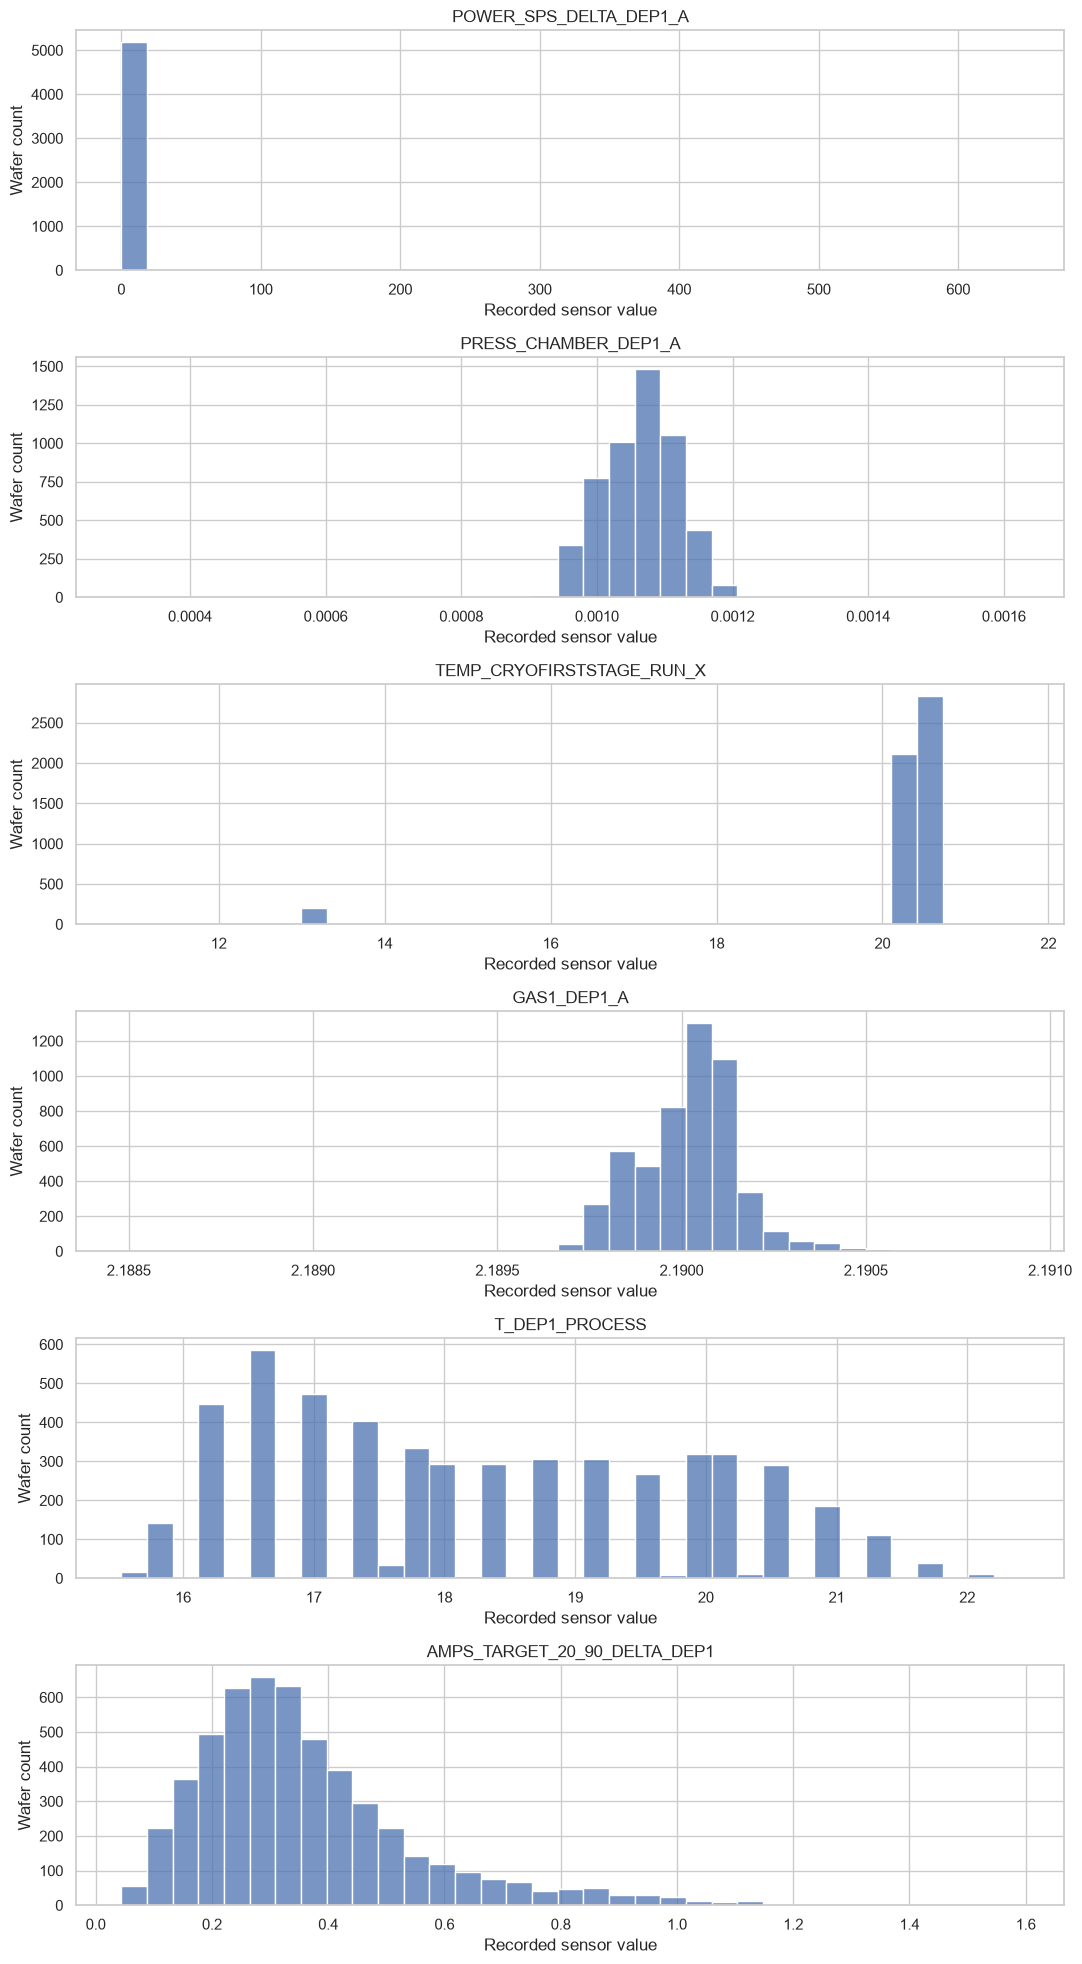

In [7]:
# Plot representative sensor distributions

if not selected_sensors:
    raise ValueError("No suitable sensors found.")

fig, axes = plt.subplots(
    len(selected_sensors),
    1,
    figsize=(11, 3.3 * len(selected_sensors))
)

axes = np.atleast_1d(axes)

for ax, sensor in zip(axes, selected_sensors):

    values = df[sensor].dropna()

    sns.histplot(
        values,
        bins=35,
        ax=ax
    )

    ax.set_title(sensor)
    ax.set_xlabel("Recorded sensor value")
    ax.set_ylabel("Wafer count")

plt.tight_layout()
plt.show()


## 5. APC Sensor Correlation with Film Thickness

Calculate Pearson correlations between APC process
variables and measured mean film thickness.

This analysis is exploratory only.

Final ML feature selection must be repeated
using training data after an appropriate split.

Top 15 APC sensors correlated with thickness:


,Pearson r
T_DEP1_PROCESS_MR,0.3165
AMPS_TARGET_DEP1_A_MR,0.3069
DCBIAS_PLATEN_DEP1_A_MR,0.2686
DCBIAS_PLATEN_DEP1_I_MR,0.2632
PRESS_IONGAUGE_BP_I_ENG1,-0.2628
PRESS_PUMP2BASE_I,-0.2402
PRESS_IONGAUGE_BP_I,-0.2401
PRESS_IONGAUGE_BP_I_ENG,-0.2260
TEMP_PLATEN_DEP1_S,0.1918
WAFERCOUNT_MR,0.1772


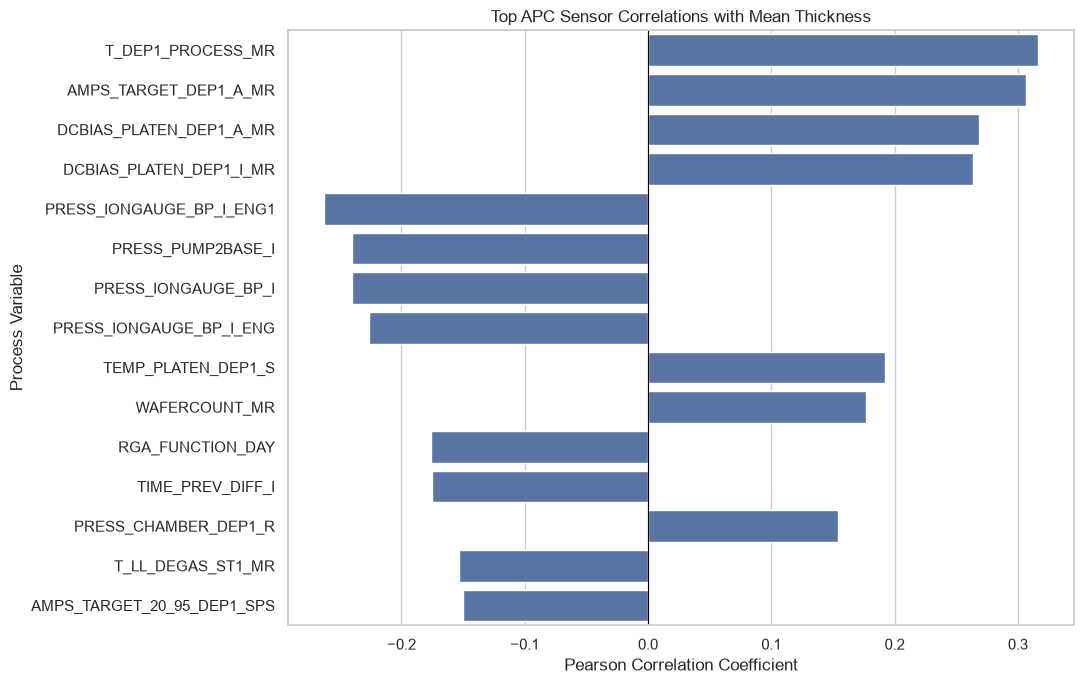

In [8]:

# STEP 2.3.7 - Correlation with thickness

thickness_corr = (
    df[apc_cols + ["mean_thickness"]]
    .corr(method="pearson")["mean_thickness"]
    .drop("mean_thickness")
    .dropna()
)

thickness_corr = (
    thickness_corr
    .reindex(
        thickness_corr.abs()
        .sort_values(ascending=False).index
    )
)

print("Top 15 APC sensors correlated with thickness:")

display(
    thickness_corr.head(15)
    .round(4)
    .to_frame("Pearson r")
)

top_thickness = thickness_corr.head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    x=top_thickness.values,
    y=top_thickness.index
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Top APC Sensor Correlations with Mean Thickness")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Process Variable")

plt.tight_layout()
plt.show()

## 6. APC Sensor Correlation with Sheet Resistance

Investigate the linear relationships between process
variables and measured mean sheet resistance.

Measured film thickness and other SPC properties are
not included as model input candidates.

The results are exploratory, not final feature selection.

Top 15 APC correlations with sheet resistance:


,Pearson r
VOLTS_TARGET_DEP1_5SEC_S,0.3026
AMPS_TARGET_DEP1_A_MR,-0.2866
T_DEP1_PROCESS_MR,-0.2773
PRESS_IONGAUGE_BP_I_ENG1,0.2533
DCBIAS_PLATEN_DEP1_A_MR,-0.2516
DCBIAS_PLATEN_DEP1_I_MR,-0.2509
VOLTS_TARGET_DEP1_S,0.2502
PRESS_PUMP2BASE_I,0.2333
PRESS_IONGAUGE_BP_I,0.2328
PRESS_IONGAUGE_BP_I_ENG,0.2157


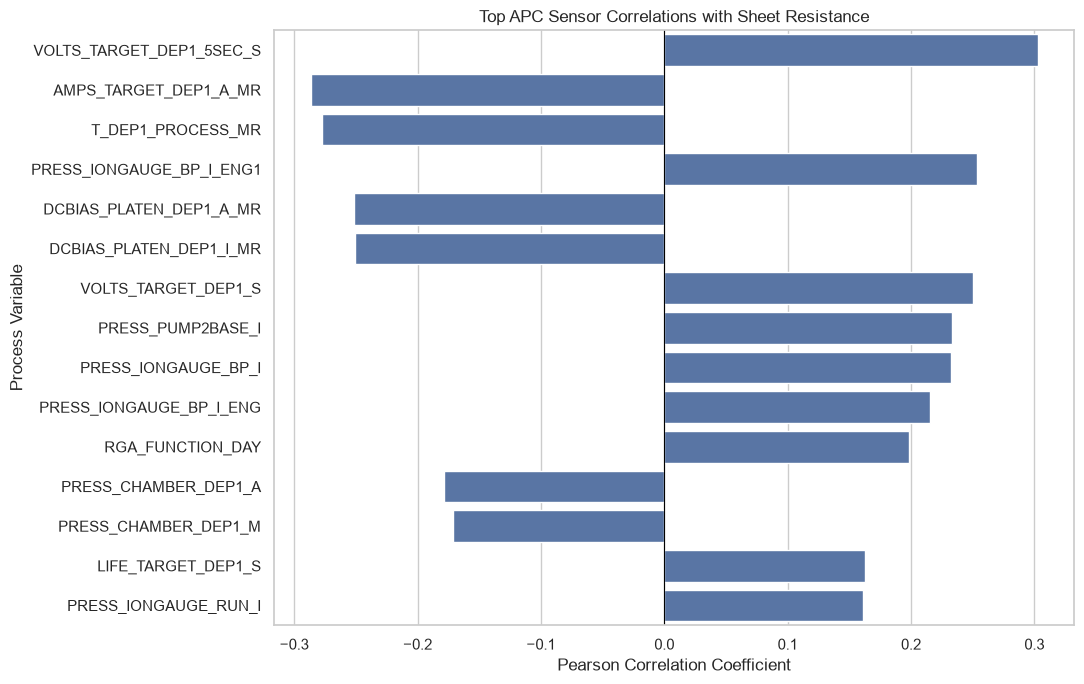

In [9]:

# STEP 2.3.8 - Correlation with resistance

resistance_corr = (
    df[apc_cols + ["mean_resistance"]]
    .corr(method="pearson")["mean_resistance"]
    .drop("mean_resistance")
    .dropna()
)

resistance_corr = (
    resistance_corr
    .reindex(
        resistance_corr.abs()
        .sort_values(ascending=False).index
    )
)

print("Top 15 APC correlations with sheet resistance:")

display(
    resistance_corr.head(15)
    .round(4)
    .to_frame("Pearson r")
)

top_resistance = resistance_corr.head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    x=top_resistance.values,
    y=top_resistance.index
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Top APC Sensor Correlations with Sheet Resistance")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Process Variable")

plt.tight_layout()
plt.show()


In [10]:

# Compare exploratory correlations

comparison = pd.DataFrame({
    "Thickness r": thickness_corr,
    "Resistance r": resistance_corr
})

comparison["Max Absolute Correlation"] = (
    comparison[
        ["Thickness r", "Resistance r"]
    ].abs().max(axis=1)
)

comparison = comparison.sort_values(
    "Max Absolute Correlation",
    ascending=False
)

display(comparison.head(20).round(4))

,Thickness r,Resistance r,Max Absolute Correlation
T_DEP1_PROCESS_MR,0.3165,-0.2773,0.3165
AMPS_TARGET_DEP1_A_MR,0.3069,-0.2866,0.3069
VOLTS_TARGET_DEP1_5SEC_S,-0.0079,0.3026,0.3026
DCBIAS_PLATEN_DEP1_A_MR,0.2686,-0.2516,0.2686
DCBIAS_PLATEN_DEP1_I_MR,0.2632,-0.2509,0.2632
PRESS_IONGAUGE_BP_I_ENG1,-0.2628,0.2533,0.2628
VOLTS_TARGET_DEP1_S,-0.0555,0.2502,0.2502
PRESS_PUMP2BASE_I,-0.2402,0.2333,0.2402
PRESS_IONGAUGE_BP_I,-0.2401,0.2328,0.2401
PRESS_IONGAUGE_BP_I_ENG,-0.2260,0.2157,0.2260


## 7. Sensor-to-Sensor Correlation

Investigate potentially redundant APC process variables.

Strong correlation between two sensors does not
automatically justify deleting either one.

Any feature removal will be decided using
training data and model evaluation.

In [11]:

# STEP 2.3.9 - Sensor correlation matrix

apc_corr_matrix = df[apc_cols].corr()

# Use upper triangle to avoid counting pairs twice
upper_triangle = apc_corr_matrix.where(
    np.triu(
        np.ones(apc_corr_matrix.shape, dtype=bool),
        k=1
    )
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Sensor 1",
    "Sensor 2",
    "Correlation"
]

high_corr_pairs["Absolute Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Absolute Correlation"] >= 0.95
].sort_values(
    "Absolute Correlation",
    ascending=False
)

print(
    "Highly correlated sensor pairs (|r| >= 0.95):",
    len(high_corr_pairs)
)

display(high_corr_pairs.head(20).round(4))

Highly correlated sensor pairs (|r| >= 0.95): 129


,Sensor 1,Sensor 2,Correlation,Absolute Correlation
9996,T_RECIPE,T_RUN_PRE_PROCESS,1.0000,1.0000
10213,T_RUN,T_RUN_ENG,1.0000,1.0000
3890,LIFE_TARGET_DEP1_A,LIFE_TARGET_RUN_I,1.0000,1.0000
4608,LIFE_TARGET_RUN_S,UTILISATION_TARGET_RUN_S,1.0000,1.0000
3888,LIFE_TARGET_DEP1_A,LIFE_TARGET_RUN_A,1.0000,1.0000
4497,LIFE_TARGET_RUN_I,UTILISATION_TARGET_RUN_A,1.0000,1.0000
4220,LIFE_TARGET_RUN_A,LIFE_TARGET_RUN_I,1.0000,1.0000
9773,T_LL_DEGAS_ST1,T_RUN_ENG,1.0000,1.0000
9772,T_LL_DEGAS_ST1,T_RUN,1.0000,1.0000
9112,TIME_POST_PROCESS_X,T_RUN,1.0000,1.0000


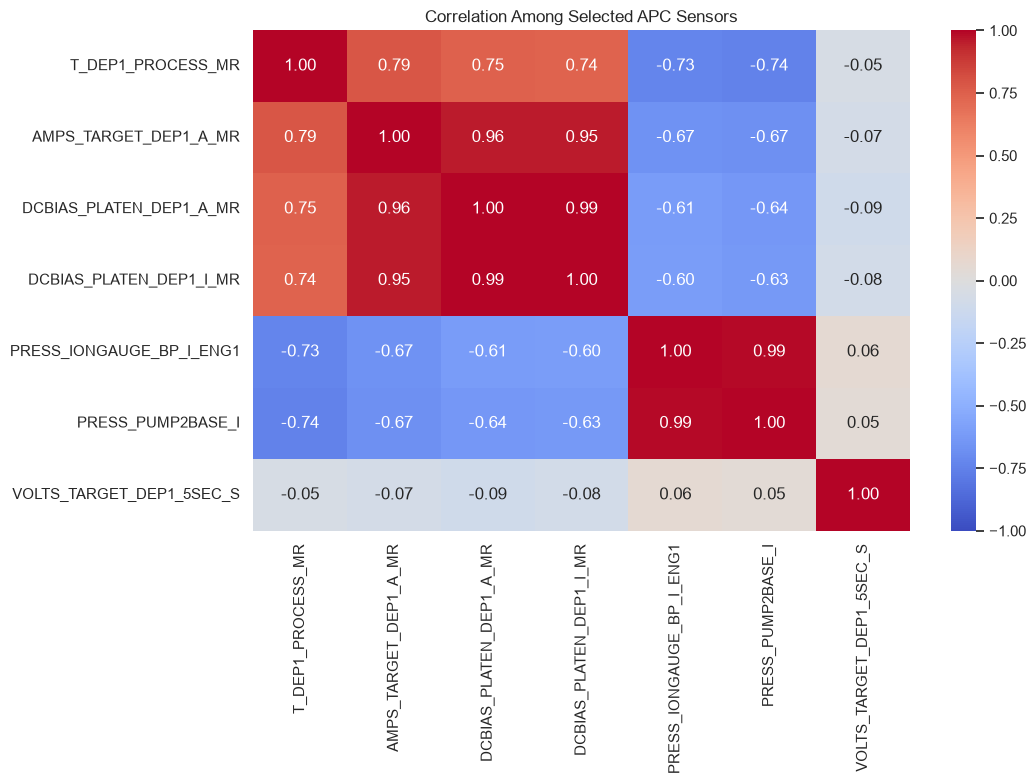

In [12]:

# Heatmap of leading exploratory APC variables

heatmap_sensors = list(
    dict.fromkeys(
        thickness_corr.head(6).index.tolist()
        + resistance_corr.head(6).index.tolist()
    )
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    df[heatmap_sensors].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Among Selected APC Sensors")

plt.tight_layout()
plt.show()

## 8. Equipment-Level Sensor Missingness

Analyse whether missing APC readings vary across
different equipment identifiers.

Missingness patterns may indicate data-collection
or equipment-configuration differences.

No causal explanation is assumed.

,WAFERCOUNT_RECIPE_MR,VOLTS_TARGET_DEP1_G,GAS2_DEP1_S,WAFERCOUNT_MR,LIFE_TARGET_RUN_I,T_RUN_ENG,PRESS_TRANSFER_RUN_X,PRESS_CHAMBER_DEP1_R,PRESS_IONGAUGE_BP_I_ENG,PRESS_IONGAUGE_BP_I_ENG1
equipment,,,,,,,,,,
equipment_1,74.00,73.52,100.00,69.74,69.50,63.83,63.83,63.83,47.99,60.28
equipment_10,38.95,37.37,76.32,25.26,25.26,15.79,14.74,14.74,88.95,11.05
equipment_11,90.16,89.52,51.43,80.95,80.32,73.65,73.33,73.33,31.11,68.57
equipment_12,51.72,50.57,27.59,42.15,41.76,33.72,33.33,33.33,70.11,29.89
equipment_13,71.69,71.23,100.00,66.59,66.36,61.48,61.48,61.48,48.26,58.93
equipment_14,70.45,70.00,100.00,66.36,66.14,60.00,60.00,60.00,50.68,57.05
equipment_15,68.75,68.25,91.75,63.75,63.50,58.25,58.00,58.00,45.25,55.00
equipment_16,55.30,54.55,38.64,46.97,46.59,37.50,37.12,37.12,68.56,31.44
equipment_2,73.33,72.86,3.33,67.62,67.38,62.38,62.14,62.14,47.38,58.81


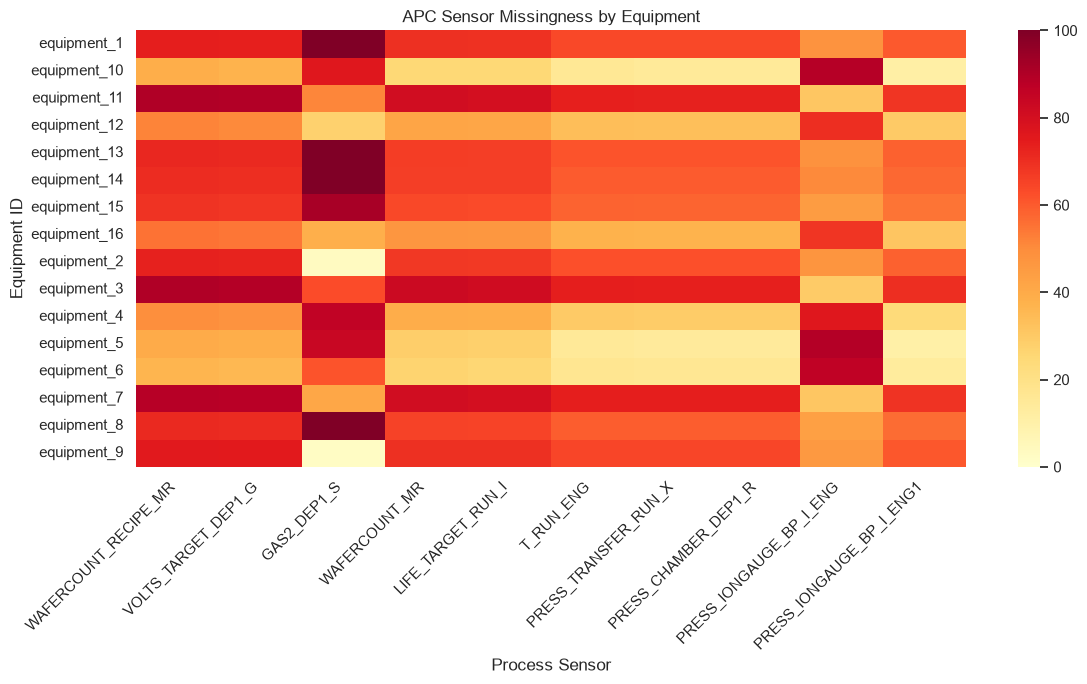

In [13]:

# STEP 2.3.10 - Missingness by equipment

top_missing_sensors = (
    apc_missing.head(10).index.tolist()
)

equipment_missing = (
    df[top_missing_sensors]
    .isna()
    .groupby(df["equipment"])
    .mean()
    * 100
)

display(equipment_missing.round(2))

plt.figure(figsize=(12, 7))

sns.heatmap(
    equipment_missing,
    cmap="YlOrRd",
    vmin=0,
    vmax=100
)

plt.title("APC Sensor Missingness by Equipment")
plt.xlabel("Process Sensor")
plt.ylabel("Equipment ID")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


## 9. Key Findings and Interpretation

### APC Process Variables
- Identified 110 numeric manufacturing process variables.
- Grouped sensors using descriptive naming conventions.
- Examined representative process-variable distributions.

### Data Completeness
- Investigated missingness across APC sensor variables.
- Identified sensors with substantial missing observations.
- Compared missingness patterns across equipment.

### Thickness Prediction
- Calculated exploratory Pearson correlations between
  APC variables and mean film thickness.
- Identified process variables associated with thickness.
- Recognised that individual correlations do not
  establish predictive performance.

### Sheet Resistance Prediction
- Investigated correlations between process variables
  and measured mean sheet resistance.
- Compared potential predictors for thickness and resistance.
- Excluded measured thickness and other SPC outputs
  from candidate prediction inputs.

### Sensor Redundancy
- Investigated highly correlated APC sensor pairs.
- Identified possible redundancy for later modelling.
- Did not remove features based on full-dataset analysis.

### Implications for STRATUM
1. Use suitable APC process measurements for virtual metrology.
2. Evaluate thickness and sheet-resistance regression separately.
3. Investigate equipment-specific sensor behaviour.
4. Handle missing values within a training-only pipeline.
5. Compare baseline and nonlinear ML models.
6. Use held-out data to establish predictive accuracy.

### Limitations
- Correlation does not establish causation.
- Missing values may affect correlation estimates.
- Sensor engineering units are not fully documented.
- Some associations may reflect equipment or time effects.
- Final ML features have not been selected.
- No model has been trained or evaluated in this notebook.